# The brachistochrone: finding the fastest path with Python
### A guided case study for first-year engineering students

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 15 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/15_Brachistochrone_Fastest_Path.ipynb)

A bead begins at rest at a high point and slides under gravity to a lower point. **Which track gets it there in the shortest time?** The shortest geometric distance is a straight line, but travel time also depends on how quickly the bead gains speed. This classical question is called the *brachistochrone problem*.

This notebook builds an answer in stages: calculate speed from familiar energy conservation, compute the exact time along each straight segment of a broken track, compare several candidate paths, construct the cycloid, and check numerical approximations against its analytical travel time. A historical circle comparison, a two-layer refraction analogy, equal-time descent on a cycloid, and dimensional scaling broaden the connections. Bisection, a short variational argument, and a numerical search over many path points are marked **optional**. We will not ask first-year students to prove the global theorem independently.

**Assumptions.** The bead starts from rest; gravity is uniform; the track is smooth enough to keep contact; friction, air resistance, and rotational kinetic energy are neglected. The bead is treated as a point mass. The downward vertical coordinate is positive. Under these assumptions its mass cancels from the calculation. A real rolling ball or rough track may rank paths differently.

This is a **self-study case study**, not an additional graded laboratory. The `.ipynb` format lets you read explanations next to executed cells and figures. Open it in JupyterLab or Jupyter Notebook through Anaconda. It needs NumPy and Matplotlib; if they are absent, install them in your Python environment with `python -m pip install numpy matplotlib`. No external data files, random draws, or SciPy installation are required.

### How to study

1. Predict which route wins before running a comparison, then explain the measured times.
2. Read every code comment: each executable line has an adjacent explanation of its role and, where useful, its physical or computational reason.
3. Change one input in a copy of the notebook, run cells in order, and use the assertions and units to investigate unexpected results.
4. Attempt the exercises near the end before opening their answer cell. Work through optional sections after the main route is clear.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 6, Engineering practice |
| **Time** | about 55 min for the essential parts |
| **Before this** | Energy conservation from mechanics; notebook 02 (bisection) and notebook 05 (NumPy). |
| **Essential** | Sections 1–4, 12 and 13. |
| **Optional on a first reading** | Sections 5–11. Sections 5, 6 and 7 are marked optional; Sections 8–11 are enrichment. |
| **Next** | 16, Hardy Cross pipe networks. |

**You have understood this notebook if you can, without looking back:**

1. Use energy conservation to show that the bead's speed depends only on how far it has dropped: v = √(2gy).
2. Compute the travel time along one straight segment, and add up the segments of a track in a loop.
3. Show numerically that the cycloid beats the straight line, although it is longer.
4. Show that using more chords brings the travel time closer to the cycloid value (convergence).
5. Name two checks from Section 12 that would catch a wrong time formula.

**Not expected of you:** The calculus of variations in Section 6.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## Reading map: Python ideas used here

| Notebook step | Programming connection |
|:--|:--|
| Define coordinates, gravity, speed, and units | Variables, `float`, arithmetic, `math.sqrt`, functions, `return` |
| Sum times along a piecewise-linear track | Lists of tuples, indices, `for`, validation, exceptions |
| Compare families of paths | Loops, conditionals, a running best value, plotting, numerical error |
| Fit a cycloid to endpoints | Functions, bisection, a `while` loop, tolerance and convergence |
| Optional search over many interior nodes | Nested loops, local improvement, work counts, algorithmic limitations |
| Compare a circle and a two-layer route | Parameterization, arrays, minimum over a grid, model assumptions |
| Release from different points and rescale inputs | Translation of coordinates, reuse of functions, dimensional checks |

**Learning goals.** Explain why speed depends on vertical drop, compute segment travel times, distinguish geometric distance from elapsed time, trace a running-best search, understand the first-step difficulty at zero speed, check a numerical calculation with an independent result, and distinguish evidence from a proof of optimality. The central lesson is how a physical model becomes a testable program.

In [1]:
# Import mathematical functions and the constant pi for geometry and square roots.
import math
# Import NumPy to make arrays of points and compare numerical results.
import numpy as np
# Import Matplotlib to draw paths, arrival times, and convergence diagnostics.
import matplotlib.pyplot as plt
# Choose a legible default figure size for embedded self-study figures.
plt.rcParams['figure.figsize'] = (7.5, 4.4)
# Use standard gravitational acceleration in metres per second squared.
g = 9.81
# Choose a horizontal endpoint separation of pi metres.
horizontal_distance = math.pi
# Choose a vertical downward drop of two metres.
vertical_drop = 2.0
# Display the chosen endpoint and explain the coordinate convention.
print(f'Start A=(0, 0) m; end B=({horizontal_distance:.6f}, {vertical_drop:.6f}) m; +y points downward')

Start A=(0, 0) m; end B=(3.141593, 2.000000) m; +y points downward


## 1. From Newtonian mechanics to speed

The bead has dropped a distance $y$ from its starting height. The loss of potential energy $mgy$ becomes kinetic energy $\tfrac12mv^2$. Thus

$$\tfrac12mv^2=mgy \quad\Longrightarrow\quad v(y)=\sqrt{2gy}.$$

The bead starts at $y=0$ with $v=0$. As it descends it speeds up. Mass $m$ cancels, so the idealized travel time does not depend on the bead's mass. This equation does not say that time is simply distance divided by final speed: the speed changes continuously along the track.

**Predict:** What is the bead's speed after dropping 0, 0.5, and 2 metres? The function below checks its input so a negative drop cannot silently enter a square root.

In [2]:
# Define a reusable speed function from conservation of mechanical energy.
def speed_at_drop(drop, gravity=g):
    # State the input units and returned speed in the function specification.
    """Return speed in m/s after a nonnegative downward drop in m."""
    # Reject negative or non-finite drops and non-physical gravity values.
    if not math.isfinite(drop) or drop < 0.0 or not math.isfinite(gravity) or gravity <= 0.0:
        # Give the caller a clear error before evaluating a square root.
        raise ValueError('drop must be nonnegative and gravity must be positive and finite')
    # Convert lost potential energy per mass into speed using v**2=2*g*drop.
    return math.sqrt(2.0 * gravity * drop)

# Visit three drops to make the acceleration effect visible numerically.
for drop in (0.0, 0.5, 2.0):
    # Print both the input drop and resulting speed with physical units.
    print(f'drop={drop:.1f} m -> speed={speed_at_drop(drop):.4f} m/s')
# Confirm the starting speed and the exact energy identity at the final drop.
assert speed_at_drop(0.0) == 0.0
# Check v**2=2*g*y numerically without claiming floats are always exact.
assert math.isclose(speed_at_drop(vertical_drop) ** 2, 2.0 * g * vertical_drop)

drop=0.0 m -> speed=0.0000 m/s
drop=0.5 m -> speed=3.1321 m/s
drop=2.0 m -> speed=6.2642 m/s


## 2. An exact time formula for one straight segment

Join two track points $(x_0,y_0)$ and $(x_1,y_1)$ by a straight segment of length $\ell=\sqrt{(x_1-x_0)^2+(y_1-y_0)^2}$. Along that segment the component of gravity in the direction of motion is constant, so acceleration along the segment is constant. The starting and ending speeds are $v_0=\sqrt{2gy_0}$ and $v_1=\sqrt{2gy_1}$. Its **average speed** is $(v_0+v_1)/2$, giving

$$\Delta t=\frac{2\ell}{v_0+v_1}.$$

This formula is *exact for a straight segment* under our assumptions. Summing it over a piecewise-linear track gives that track's time. A polygon that approximates a curved path has a separate **geometric approximation error**: its chords are not the original curve.

If a path begins with a horizontal segment at $y=0$, the bead has zero speed and no component of gravity along the segment. Its travel time is infinite in the ideal model. For a path that starts steeply, the first segment has $v_0=0$ but $v_1>0$, so the formula gives a finite time. We allow a vertical segment, although its two $x$ coordinates are equal.

In [3]:
# Define the exact travel time along one straight track segment.
def segment_time(start, end, gravity=g):
    # Describe the points and the returned time in seconds.
    """Return time in s along a segment between (x, downward_y) points."""
    # Unpack the starting point into horizontal and downward coordinates.
    x0, y0 = start
    # Unpack the endpoint in the same coordinate order.
    x1, y1 = end
    # Reject coordinates that cannot describe a finite point below the start level.
    if not all(math.isfinite(z) for z in (x0, y0, x1, y1)) or y0 < 0.0 or y1 < 0.0:
        # State the admissible coordinate domain before taking a square root.
        raise ValueError('points must be finite and downward coordinates nonnegative')
    # Keep travel direction to the right, while permitting vertical movement.
    if x1 < x0:
        # Reject a backwards segment for this notebook's path convention.
        raise ValueError('path x coordinates must not decrease')
    # Calculate physical segment length using a stable hypotenuse operation.
    length = math.hypot(x1 - x0, y1 - y0)
    # Reject a duplicate point because it contributes no track segment.
    if length == 0.0:
        # Identify the repeated input rather than concealing it in a sum.
        raise ValueError('consecutive path points must differ')
    # Calculate the speed at the start from its downward drop.
    initial_speed = speed_at_drop(y0, gravity)
    # Calculate the speed at the end using the same energy equation.
    final_speed = speed_at_drop(y1, gravity)
    # Detect a horizontal segment at the starting level with no driving force.
    if initial_speed + final_speed == 0.0:
        # Represent failure to depart as infinite idealized travel time.
        return math.inf
    # Divide distance by the mean of the endpoint speeds for constant acceleration.
    return 2.0 * length / (initial_speed + final_speed)

# Define a track's total time as the sum over its straight pieces.
def path_time(points, gravity=g):
    # Document the ordered points and returned total time.
    """Sum exact segment times for a piecewise-linear track from (0, 0)."""
    # Require a starting point and at least one different endpoint.
    if len(points) < 2 or not math.isclose(points[0][0], 0.0) or not math.isclose(points[0][1], 0.0):
        # Reject an incomplete route or a different reference height.
        raise ValueError('supply at least two points, beginning at (0, 0)')
    # Initialize the running sum before visiting any segments.
    total_time = 0.0
    # Visit indices of adjacent pairs; the final index is len(points)-2.
    for index in range(len(points) - 1):
        # Add the time along one straight piece to the accumulated time.
        total_time += segment_time(points[index], points[index + 1], gravity)
    # Return the total so the caller can compare candidate paths.
    return total_time

### First checks: straight, broken, and vertical-then-horizontal tracks

We compare paths from $A=(0,0)$ to $B=(\pi,2)$ metres. A straight line can be represented by one segment or split into two **collinear** segments; both representations should have the same time. A broken path descends steeply to $(0.4,1.0)$ m, then turns toward $B$. A vertical-first path reaches $(0,2)$ m and then travels horizontally. Each comparison is a test of the physical model and of the `path_time` loop.

In [4]:
# Store the common destination as an (x, downward_y) tuple in metres.
end_point = (horizontal_distance, vertical_drop)
# Make a straight track with only its starting and ending points.
straight_points = [(0.0, 0.0), end_point]
# Insert a point halfway along the same line without changing its geometry.
split_straight_points = [(0.0, 0.0), (horizontal_distance / 2.0, vertical_drop / 2.0), end_point]
# Descend steeply first, then cross the remaining horizontal distance.
broken_points = [(0.0, 0.0), (0.4, 1.0), end_point]
# Drop vertically to full depth, then move horizontally at constant speed.
vertical_then_flat_points = [(0.0, 0.0), (0.0, vertical_drop), end_point]
# Evaluate the one-segment straight route using the reusable path function.
straight_time = path_time(straight_points)
# Evaluate the identical straight geometry after splitting it into two pieces.
split_straight_time = path_time(split_straight_points)
# Evaluate a longer two-piece path that gains vertical speed early.
broken_time = path_time(broken_points)
# Evaluate the vertical-then-horizontal alternative under the same assumptions.
vertical_then_flat_time = path_time(vertical_then_flat_points)
# Compute the straight time independently from its total length and final speed.
straight_formula = 2.0 * math.hypot(horizontal_distance, vertical_drop) / speed_at_drop(vertical_drop)
# Report the routes on a common seconds scale.
for label, result in [('Straight', straight_time), ('Steep broken', broken_time), ('Vertical then flat', vertical_then_flat_time)]:
    # Use consistent precision so each difference is visible.
    print(f'{label:18s}: {result:.6f} s')
# Check a split straight line against both the single segment and independent formula.
assert math.isclose(straight_time, split_straight_time, rel_tol=1e-12)
# Check the segment calculation against the hand-derived full-line result.
assert math.isclose(straight_time, straight_formula, rel_tol=1e-12)
# Check the intended example ordering without presenting it as a general theorem.
assert broken_time < vertical_then_flat_time < straight_time

Straight          : 1.189043 s
Steep broken      : 1.032103 s
Vertical then flat: 1.140068 s


In [5]:
# Construct a horizontal path at the initial height where the bead cannot start.
stuck_path = [(0.0, 0.0), (0.5, 0.0), end_point]
# Calculate its idealized time without attempting to divide by zero.
stuck_time = path_time(stuck_path)
# Print the non-finite result as a physical diagnosis of no initial motion.
print('Horizontal first at rest:', stuck_time)
# Verify that the idealized model treats this route as never departing.
assert math.isinf(stuck_time)

Horizontal first at rest: inf


**Checkpoint.** The straight path takes about 1.189 s; the steep broken track about 1.032 s. The broken track is geometrically longer, yet it gains speed early enough to arrive sooner. The vertical-then-horizontal route is faster than straight in this example but does not win among these candidates. Comparing a few paths **cannot establish a global optimum**.

## 3. Search within a family of curves

Before seeing the exact solution, try $y(x)=H(x/L)^p$ for $0\le x\le L$. At $p=1$ this is the straight line. For $0<p<1$ the curve drops rapidly near the start. We approximate each smooth curve by 400 straight segments and evaluate its polygonal time. We then use a loop and a running best value to search a finite list of exponents. The winning exponent is best **within this tested family and grid**, not among all possible curves.

In [6]:
# Define a sampled power-law path between the chosen start and endpoint.
def power_path(exponent, segments=400):
    # State that the return value is an ordered list of (x, downward_y) tuples.
    """Return polygon points on y=H*(x/L)**exponent for exponent>0."""
    # Reject invalid exponents and segment counts before constructing the path.
    if not math.isfinite(exponent) or exponent <= 0.0 or isinstance(segments, bool) or not isinstance(segments, int) or segments < 1:
        # Explain the parameter requirements for a meaningful sampled path.
        raise ValueError('exponent must be positive and segments a positive integer')
    # Include both endpoints by requesting one more point than segments.
    x_values = np.linspace(0.0, horizontal_distance, segments + 1)
    # Start a list that will preserve the geometric order of the points.
    points = []
    # Visit every horizontal position, including x=0 and x=L.
    for x in x_values:
        # Calculate the downward drop from the power-law family.
        y = vertical_drop * (x / horizontal_distance) ** exponent
        # Append a plain tuple that path_time can understand.
        points.append((float(x), float(y)))
    # Return the complete piecewise-linear approximation of the smooth curve.
    return points

# Set the first best time above every finite candidate result.
best_family_time = math.inf
# Mark that no exponent has been selected before the first comparison.
best_exponent = None
# Keep all tested exponent-time pairs for a later plot.
family_results = []
# Try 20 exponents from 0.25 through 1.20 in steps of 0.05.
for index in range(20):
    # Construct one candidate exponent from its integer loop index.
    exponent = 0.25 + 0.05 * index
    # Approximate its curved track by 400 straight segments.
    candidate_points = power_path(exponent, segments=400)
    # Sum exact segment times for the polygon, not an exact smooth-curve integral.
    candidate_time = path_time(candidate_points)
    # Record the pair to inspect the full comparison later.
    family_results.append((exponent, candidate_time))
    # Keep the fastest observed candidate in this finite family.
    if candidate_time < best_family_time:
        # Replace the previous best time by the new smaller time.
        best_family_time = candidate_time
        # Keep the matching exponent needed to reconstruct that track.
        best_exponent = exponent
# Display the selected exponent and its approximate travel time.
print(f'Fastest tested power curve: p={best_exponent:.2f}, polygon time={best_family_time:.6f} s')
# Check that the selected curved candidate beats the straight case here.
assert best_family_time < straight_time

Fastest tested power curve: p=0.45, polygon time=1.011506 s


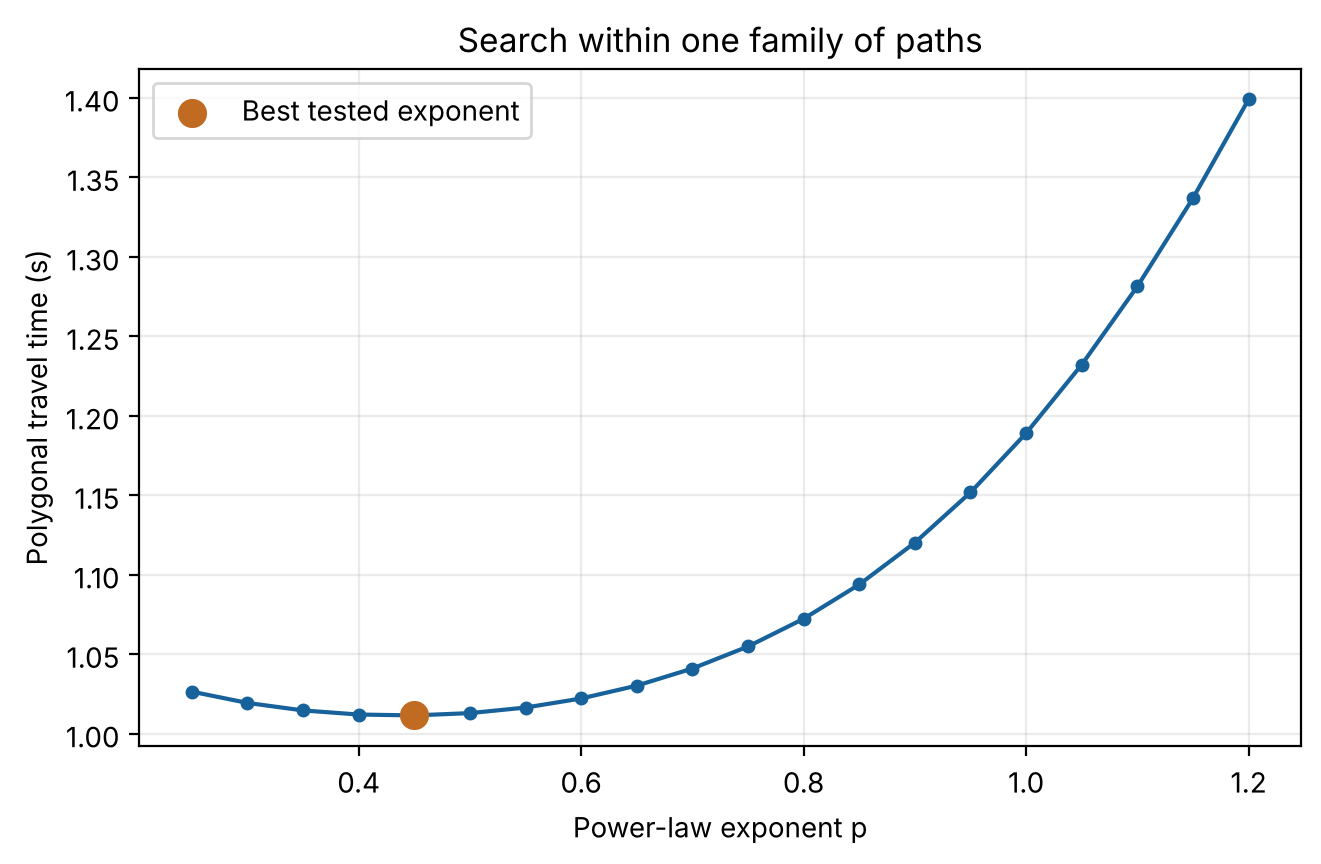

In [7]:
# Extract tested exponents from the stored tuple list for plotting.
exponents = [pair[0] for pair in family_results]
# Extract their matching travel times without changing the list order.
family_times = [pair[1] for pair in family_results]
# Open a figure of observed time against the chosen shape parameter.
fig, ax = plt.subplots()
# Join tested points to show the trend while retaining the discrete markers.
ax.plot(exponents, family_times, 'o-', color='#17629a', markersize=4)
# Mark the best tested exponent separately for a clear reading point.
ax.scatter([best_exponent], [best_family_time], color='#c06a22', s=90, zorder=3, label='Best tested exponent')
# Label the axes and clarify that the times refer to polygons.
ax.set(xlabel='Power-law exponent p', ylabel='Polygonal travel time (s)', title='Search within one family of paths')
# Support approximate reading without implying more precision than the samples.
ax.grid(alpha=0.25)
# Identify the selected candidate in the plot.
ax.legend()
# Show the complete set of tested exponent-time pairs below the cell.
plt.show()

**Pause and reflect.** The graph has a lowest tested point, but the exponent grid may miss the best exponent within this family. Even the best power law is not necessarily the best *path*. Also, 400 chords approximate each curved track; a finite chord calculation should not be confused with an exact continuum travel time. These are two different restrictions: search-family error and path-discretization error.

## 4. The analytical solution: a cycloid

For the idealized frictionless problem, the fastest path is an arc of a **cycloid**. With a downward positive $y$ coordinate, write

$$x(\theta)=a(\theta-\sin\theta),\qquad
y(\theta)=a(1-\cos\theta).$$

Here $a$ is a length scale and $\theta$ is a dimensionless parameter. For our special endpoint $B=(\pi,2)$ m, choosing $a=1$ m and $\theta_1=\pi$ gives $x=\pi$ m and $y=2$ m. At the start, $dx/d\theta=dy/d\theta=0$ and the curve has a vertical tangent as it leaves the cusp. Its travel time remains finite.

For $0<\theta\le\pi$, $ds/d\theta=2a\sin(\theta/2)$ and $v=2\sqrt{ag}\sin(\theta/2)$. Their ratio is constant, $dt/d\theta=\sqrt{a/g}$; at $\theta=0$ this is interpreted by a limit. Thus

$$T_{\mathrm{cycloid}}=\theta_1\sqrt{a/g}=\pi/\sqrt{g}\quad\text{for our endpoint.}$$

The fact that this stationary curve is the **global** least-time route is a mathematical result, not a conclusion proved by our finite comparisons. An optional section below shows the first-order variational condition, and the references give a proof beyond this course's scope.

In [8]:
# Define a generator of points on a cycloid from theta=0 to a chosen end angle.
def cycloid_path(scale, theta_end, segments):
    # Describe both parameters and the returned ordered point list.
    """Return segments+1 cycloid points (x, downward_y), in metres."""
    # Require a positive length scale, a first-arch angle, and a usable resolution.
    if not math.isfinite(scale) or scale <= 0.0 or not math.isfinite(theta_end) or not 0.0 < theta_end < 2.0 * math.pi or isinstance(segments, bool) or not isinstance(segments, int) or segments < 1:
        # Reject a parameterization that does not describe the intended first arch.
        raise ValueError('require scale>0, 0<theta_end<2*pi, and segments>=1')
    # Sample the parameter uniformly and include both endpoint angles.
    angles = np.linspace(0.0, theta_end, segments + 1)
    # Start a list compatible with the earlier polygonal path-time function.
    points = []
    # Convert every parameter value into a physical point.
    for theta in angles:
        # Compute the horizontal position along the inverted cycloid.
        x = scale * (theta - math.sin(theta))
        # Compute the downward drop from the cusp.
        y = scale * (1.0 - math.cos(theta))
        # Save a pair of ordinary floats in path order.
        points.append((x, y))
    # Return the chord endpoints used to approximate the smooth curve.
    return points

# Use the simple exact endpoint scale of one metre.
cycloid_scale = 1.0
# Stop at the bottom of the first arch, theta=pi.
cycloid_end_angle = math.pi
# Generate an initial 100-segment polygon for numerical comparison.
cycloid_points_100 = cycloid_path(cycloid_scale, cycloid_end_angle, 100)
# Calculate the exact smooth-curve time from the constant dt/dtheta result.
cycloid_exact_time = cycloid_end_angle * math.sqrt(cycloid_scale / g)
# Compute the travel time of the polygon through 101 sampled cycloid points.
cycloid_polygon_time = path_time(cycloid_points_100)
# Print both times so the geometric approximation error is explicit.
print(f'Cycloid smooth: {cycloid_exact_time:.9f} s; 100-chord polygon: {cycloid_polygon_time:.9f} s')
# Check the final sampled point against the selected destination.
assert np.allclose(cycloid_points_100[-1], end_point, atol=1e-12)
# Check the specific candidate ordering without treating it as a proof by itself.
assert cycloid_exact_time < best_family_time < broken_time < straight_time

Cycloid smooth: 1.003033340 s; 100-chord polygon: 1.003043695 s


### Distance and time answer different questions

For this half-cycloid, integrating $ds/d\theta=2a\sin(\theta/2)$ from 0 to $\pi$ gives an **arc length of $4a=4$ m**. The straight line between the endpoints has length $\sqrt{\pi^2+2^2}\approx3.724$ m. We can compute polygonal lengths with the same list-of-points representation used for time. The 100-chord approximation is slightly shorter than the smooth cycloid arc, because chords cut across a curve.

In [9]:
# Define the geometric length of a piecewise-linear track independently of time.
def polygon_length(points):
    # Document the physical unit and the input's point ordering.
    """Return the total length in m of an ordered polygonal path."""
    # Require at least one segment before starting the length sum.
    if len(points) < 2:
        # Reject an incomplete path rather than report a misleading zero length.
        raise ValueError('a path requires at least two points')
    # Initialize a running sum of geometric distances.
    total_length = 0.0
    # Visit indices zero through len(points)-2 so each adjacent pair appears once.
    for index in range(len(points) - 1):
        # Calculate one segment's horizontal and downward differences.
        dx = points[index + 1][0] - points[index][0]
        # Calculate the matching vertical difference for the same segment.
        dy = points[index + 1][1] - points[index][1]
        # Add Euclidean length without using any speed or travel-time formula.
        total_length += math.hypot(dx, dy)
    # Return geometric distance to keep it separate from elapsed time.
    return total_length

# Measure the shortest-distance straight line between the common endpoints.
straight_length = polygon_length(straight_points)
# Measure the deliberately steep broken route over its two pieces.
broken_length = polygon_length(broken_points)
# Measure the 100-chord approximation of the cycloid's smooth length.
cycloid_polygon_length = polygon_length(cycloid_points_100)
# Use the exact arc-length integral for the half-cycloid as an independent check.
cycloid_exact_length = 4.0 * cycloid_scale
# Print distances next to times to prevent them from being conflated.
print(f'Straight: length={straight_length:.6f} m, time={straight_time:.6f} s')
# Display the two-piece route on the same length and time scales.
print(f'Broken:   length={broken_length:.6f} m, time={broken_time:.6f} s')
# Display the smooth cycloid and its distinct polygonal length estimate.
print(f'Cycloid:  smooth length={cycloid_exact_length:.6f} m, time={cycloid_exact_time:.6f} s; polygon length={cycloid_polygon_length:.6f} m')
# Confirm the straight track is geometrically shorter in this comparison.
assert straight_length < broken_length < cycloid_exact_length
# Confirm the 100 straight chords approach the longer smooth arc from below here.
assert cycloid_polygon_length < cycloid_exact_length

Straight: length=3.724192 m, time=1.189043 s
Broken:   length=3.995308 m, time=1.032103 s
Cycloid:  smooth length=4.000000 m, time=1.003033 s; polygon length=3.999959 m


**Checkpoint.** The analytical cycloid takes about 1.003 s, compared with about 1.189 s for the shorter straight track. Its 100-chord polygon takes slightly longer than the smooth cycloid because it is a *different track*. We can shrink that discrepancy by sampling more points. Do not compute $ds/v$ by plugging $y=0$ into the integral's first point: it has the indeterminate form $0/0$ in the cycloid parameter. The exact $dt/d\theta$ limit and finite straight-segment formula handle the start correctly.

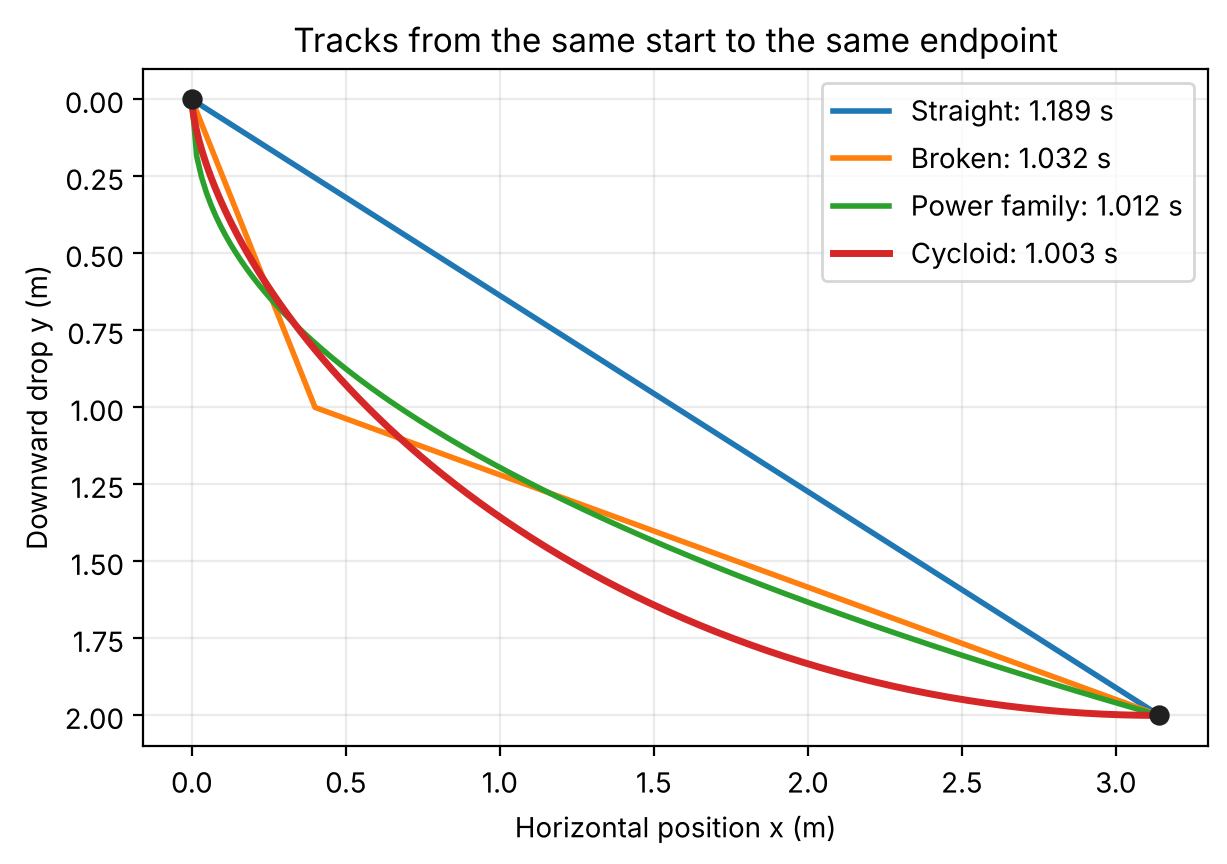

In [10]:
# Build points for the fastest tested power-law curve at plotting resolution.
best_power_points = power_path(best_exponent, segments=200)
# Create a drawing of four tracks that share identical start and end points.
fig, ax = plt.subplots()
# Connect the two endpoints to show the shortest-distance straight path.
ax.plot([point[0] for point in straight_points], [point[1] for point in straight_points], linewidth=2, label=f'Straight: {straight_time:.3f} s')
# Draw the broken track to make its early steep descent visible.
ax.plot([point[0] for point in broken_points], [point[1] for point in broken_points], linewidth=2, label=f'Broken: {broken_time:.3f} s')
# Draw the best curve found within the restricted power-law family.
ax.plot([point[0] for point in best_power_points], [point[1] for point in best_power_points], linewidth=2, label=f'Power family: {best_family_time:.3f} s')
# Draw the analytical cycloid through its sampled points.
ax.plot([point[0] for point in cycloid_points_100], [point[1] for point in cycloid_points_100], linewidth=2.5, label=f'Cycloid: {cycloid_exact_time:.3f} s')
# Mark the common start and end without covering the paths.
ax.scatter([0.0, horizontal_distance], [0.0, vertical_drop], color='#202020', s=40, zorder=4)
# Put larger downward coordinates lower in the figure, matching physical orientation.
ax.invert_yaxis()
# Use equal length scales to make geometric distance comparisons meaningful.
ax.set_aspect('equal', adjustable='box')
# Label coordinate directions and physical units explicitly.
ax.set(xlabel='Horizontal position x (m)', ylabel='Downward drop y (m)', title='Tracks from the same start to the same endpoint')
# Add a light grid and identify all four routes by their times.
ax.grid(alpha=0.25)
# Place route labels where the curves remain visible.
ax.legend(loc='upper right')
# Show the four tracks on equal physical scales with their arrival times.
plt.show()

**Interpreting the path plot.** The cycloid initially points almost vertically downward, so it gains speed early; it later uses that speed to cover horizontal distance. The labels report time, not geometric length. The cycloid result applies to an ideal point bead with frictionless sliding. Our tested power-law curves and broken lines are useful comparisons, but no finite collection of tests proves that one path beats every admissible path.

### Convergence: chords versus a smooth cycloid

Our `segment_time` formula is exact *for each straight chord*. The polygon made from sampled cycloid points is not the smooth cycloid. We can vary its number of segments and compare with the independent exact time. The expected polygonal error should shrink as we refine this particular approximation, but we should inspect the data rather than promise a universal rate.

 10 segments: T=1.004109075 s, T-T_exact=1.075735094e-03 s
 20 segments: T=1.003296571 s, T-T_exact=2.632307110e-04 s
 50 segments: T=1.003074931 s, T-T_exact=4.159060229e-05 s
100 segments: T=1.003043695 s, T-T_exact=1.035463220e-05 s
200 segments: T=1.003035924 s, T-T_exact=2.583319234e-06 s
400 segments: T=1.003033986 s, T-T_exact=6.451648389e-07 s


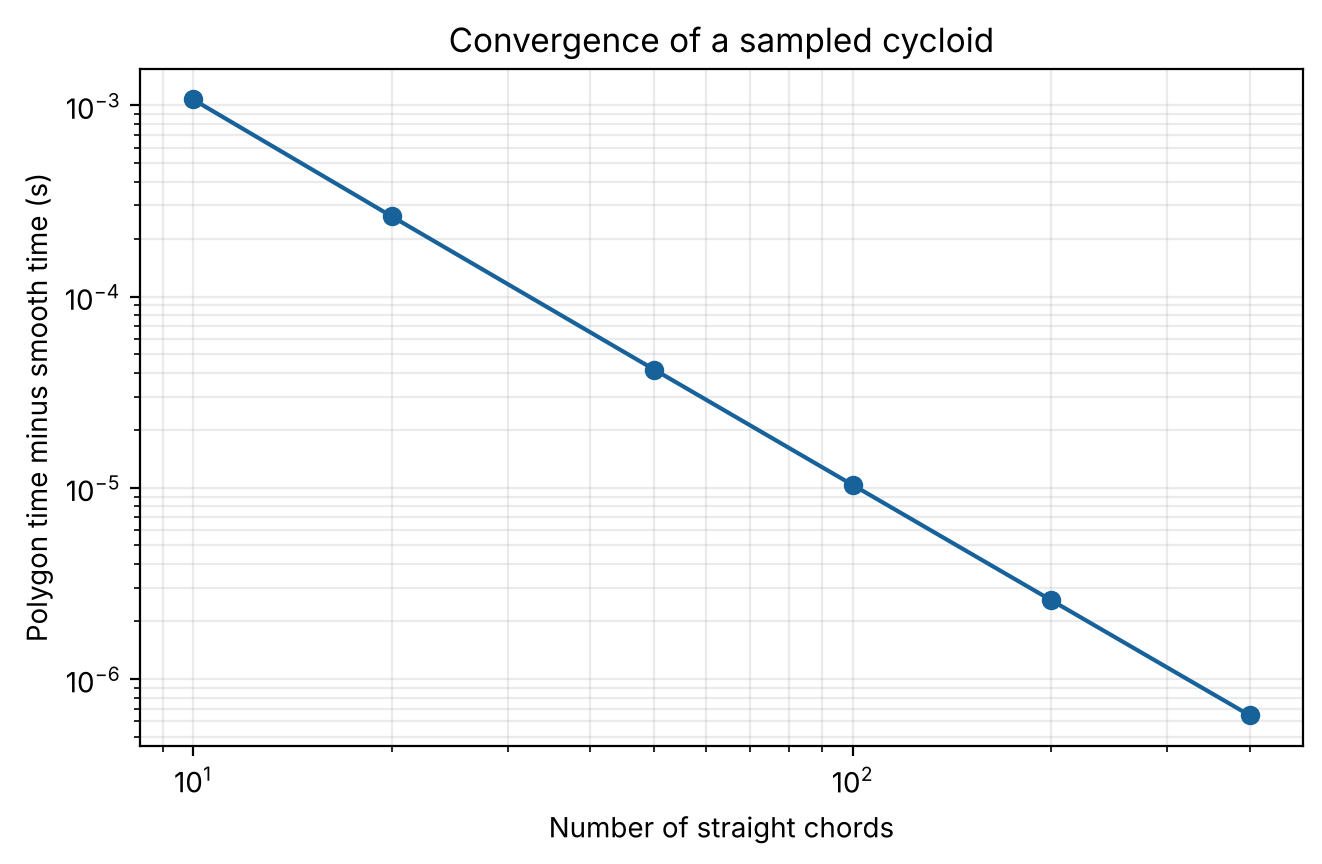

In [11]:
# Choose several polygon resolutions, keeping the same cycloid and endpoint.
segment_counts = [10, 20, 50, 100, 200, 400]
# Store absolute discrepancies from the smooth analytical travel time.
polygon_errors = []
# Recompute the polygonal track at each selected resolution.
for count in segment_counts:
    # Sample count+1 cycloid points to form count straight segments.
    sampled_track = cycloid_path(cycloid_scale, cycloid_end_angle, count)
    # Sum exact times along its straight chords.
    approximation = path_time(sampled_track)
    # Subtract the known smooth-curve time to measure path approximation error.
    error = approximation - cycloid_exact_time
    # Save the error in the same order as the segment-count list.
    polygon_errors.append(error)
    # Display both the numerical time and its difference from the reference.
    print(f'{count:3d} segments: T={approximation:.9f} s, T-T_exact={error:.9e} s')
    # Confirm these particular polygon tracks do not beat the exact global minimum.
    assert error >= -1e-10
# Check that the final, more resolved example is closer than the first one.
assert polygon_errors[-1] < polygon_errors[0]

# Open a figure of the observed numerical error against polygon resolution.
fig, ax = plt.subplots()
# Use log axes to show changes across multiple resolutions and error scales.
ax.loglog(segment_counts, polygon_errors, 'o-', color='#17629a')
# State that the vertical quantity is travel-time error in seconds.
ax.set(xlabel='Number of straight chords', ylabel='Polygon time minus smooth time (s)', title='Convergence of a sampled cycloid')
# Add a light grid on both major and minor ticks for reading the trend.
ax.grid(alpha=0.25, which='both')
# Render the convergence diagnostic below its calculation.
plt.show()

### When does each bead reach a horizontal position?

The total time tells us who reaches the endpoint first. We can also compare **elapsed time versus horizontal position**. On the cycloid $t(\theta)=\sqrt{a/g}\,\theta$ and $x(\theta)=a(\theta-\sin\theta)$. Along the straight line, distance and $x$ are proportional, and constant acceleration from rest gives $x/L=(t/T_{\rm straight})^2$, so $t(x)=T_{\rm straight}\sqrt{x/L}$. This is a second way to test the physics and helps explain why an initially steep path can win.

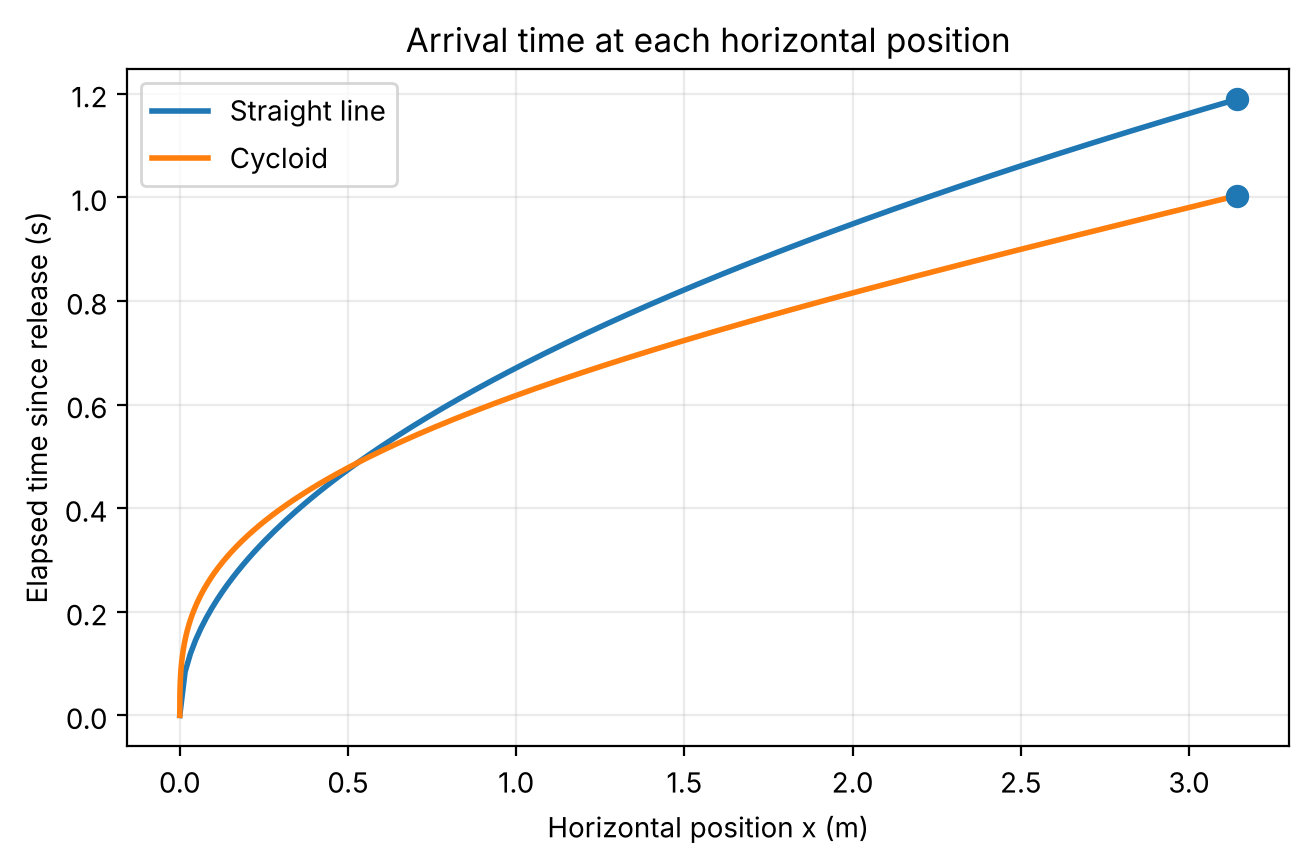

In [12]:
# Generate evenly spaced cycloid parameters from start to end.
race_angles = np.linspace(0.0, cycloid_end_angle, 201)
# Convert each parameter to a horizontal position on the cycloid.
race_cycloid_x = cycloid_scale * (race_angles - np.sin(race_angles))
# Convert each parameter directly to elapsed time using dt/dtheta.
race_cycloid_t = math.sqrt(cycloid_scale / g) * race_angles
# Generate horizontal positions for the straight-track comparison.
race_straight_x = np.linspace(0.0, horizontal_distance, 201)
# Use constant-acceleration motion from rest to determine arrival time at x.
race_straight_t = straight_time * np.sqrt(race_straight_x / horizontal_distance)
# Open a graph with the same arrival-time unit for both paths.
fig, ax = plt.subplots()
# Plot when the bead on the straight path reaches each horizontal coordinate.
ax.plot(race_straight_x, race_straight_t, linewidth=2, label='Straight line')
# Plot when the bead on the cycloid reaches each horizontal coordinate.
ax.plot(race_cycloid_x, race_cycloid_t, linewidth=2, label='Cycloid')
# Label the endpoint times to keep the earlier comparison visible.
ax.scatter([horizontal_distance, horizontal_distance], [straight_time, cycloid_exact_time], s=55, zorder=3)
# Explain both quantities and their physical units on the axes.
ax.set(xlabel='Horizontal position x (m)', ylabel='Elapsed time since release (s)', title='Arrival time at each horizontal position')
# Add a light grid and distinguish the two paths.
ax.grid(alpha=0.25)
# Show which curve corresponds to each track.
ax.legend()
# Render the time-position comparison in the notebook.
plt.show()

**Checkpoint.** Near the start, the cycloid bead lags in **horizontal position** because its track points steeply downward. After gaining speed, it overtakes the straight-line bead; the arrival-time curves cross near $x=0.5$ m. It reaches the common endpoint first. The two tracks have different downward coordinates at the same $x$, so the energy equation does not imply equal speeds at that $x$. This plot helps explain why early horizontal progress and earliest final arrival are different questions.

## 5. Optional: fit a cycloid to another endpoint by bisection

For an endpoint $(L,H)$, the two cycloid equations imply

$$\frac{L}{H}=\frac{\theta_1-\sin\theta_1}{1-\cos\theta_1},
\qquad a=\frac{H}{1-\cos\theta_1}.$$

We can solve the first scalar equation for $\theta_1$ with **bisection** (notebook 02), then calculate $a$. We choose a bracket entirely inside the first arch, away from $\theta=0$ and $2\pi$ where the ratio has a removable or singular numerical issue. The supplied bracket works for the two examples below; a different endpoint can require a different bracket. The function checks that the target ratio is actually bracketed before starting its bounded loop. A solution with $\theta_1>\pi$ descends and then climbs toward its endpoint; the main example ends at $\pi$ and avoids that extra complication.

In [13]:
# Define the ratio x/y for a cycloid point at a non-singular parameter angle.
def cycloid_ratio(theta):
    # State the dimensionless quantity used to match endpoints.
    """Return (theta-sin(theta))/(1-cos(theta)) for 0<theta<2*pi."""
    # Keep the evaluation away from zero and the second cusp.
    if not math.isfinite(theta) or not 0.0 < theta < 2.0 * math.pi:
        # Describe the domain of the endpoint-matching equation.
        raise ValueError('theta must be strictly between 0 and 2*pi')
    # Divide the horizontal cycloid factor by its vertical factor.
    return (theta - math.sin(theta)) / (1.0 - math.cos(theta))

# Solve the endpoint ratio by keeping a bracket around its root.
def fit_cycloid_endpoint(horizontal, drop, lower=0.1, upper=5.5, width_tolerance=1e-12, max_steps=100):
    # Describe the length scale, final angle, and iteration count returned.
    """Return (scale, theta_end, steps) for a bracketed first-arch endpoint."""
    # Reject non-physical endpoints before taking their ratio.
    if not math.isfinite(horizontal) or not math.isfinite(drop) or horizontal <= 0.0 or drop <= 0.0:
        # Explain that the target must lie rightward and below the start.
        raise ValueError('horizontal and drop must be positive finite lengths')
    # Reject a non-positive stopping width or a non-integer work cap.
    if not math.isfinite(width_tolerance) or width_tolerance <= 0.0 or isinstance(max_steps, bool) or not isinstance(max_steps, int) or max_steps < 1:
        # Keep the while loop's stopping rule meaningful and bounded.
        raise ValueError('require positive tolerance and positive integer max_steps')
    # Divide the endpoint's horizontal distance by its drop to obtain the target ratio.
    target_ratio = horizontal / drop
    # Verify ordered interior angles and that their ratios straddle the target.
    if not 0.0 < lower < upper < 2.0 * math.pi or not cycloid_ratio(lower) < target_ratio < cycloid_ratio(upper):
        # Ask for a wider or better-positioned bracket instead of guessing a root.
        raise ValueError('the endpoint ratio is not bracketed by these angles')
    # Initialize a counter before the first interval halving.
    steps = 0
    # Stop when the angular bracket is sufficiently narrow or work is exhausted.
    while upper - lower > width_tolerance and steps < max_steps:
        # Split the remaining angle interval into equal halves.
        midpoint = (lower + upper) / 2.0
        # Compare the cycloid ratio at the midpoint with the desired ratio.
        if cycloid_ratio(midpoint) < target_ratio:
            # Keep the upper half because the root lies to the right.
            lower = midpoint
        # Handle a midpoint at or to the right of the desired root.
        else:
            # Keep the lower half because the root lies to the left.
            upper = midpoint
        # Count one completed halving so the maximum-work cap remains effective.
        steps += 1
    # Detect an insufficient iteration cap rather than claiming convergence.
    if upper - lower > width_tolerance:
        # Tell the caller that the requested width was not reached.
        raise RuntimeError('bisection did not converge within max_steps')
    # Use the centre of the final narrow bracket as the fitted end angle.
    theta_end = (lower + upper) / 2.0
    # Match the vertical endpoint to determine the cycloid length scale.
    scale = drop / (1.0 - math.cos(theta_end))
    # Return the fitted parameters and a count of the loop's work.
    return scale, theta_end, steps

# Fit the simple endpoint whose exact solution is scale=1 and theta=pi.
fitted_scale, fitted_angle, fit_steps = fit_cycloid_endpoint(horizontal_distance, vertical_drop)
# Display the recovered parameters and the number of interval halvings.
print(f'Original endpoint: a={fitted_scale:.9f} m, theta={fitted_angle:.9f}, steps={fit_steps}')
# Independently verify the recovered horizontal and downward coordinates.
assert math.isclose(fitted_scale * (fitted_angle - math.sin(fitted_angle)), horizontal_distance, abs_tol=1e-10)
# Check the vertical endpoint and known exact special-case parameters.
assert math.isclose(fitted_scale * (1.0 - math.cos(fitted_angle)), vertical_drop, abs_tol=1e-10)
# Recover the known half-cycloid angle and scale within numerical tolerance.
assert math.isclose(fitted_angle, math.pi, abs_tol=1e-10) and math.isclose(fitted_scale, 1.0, abs_tol=1e-10)

Original endpoint: a=1.000000000 m, theta=3.141592654, steps=43


In [14]:
# Choose a second lower-right endpoint with no especially simple exact angle.
second_horizontal, second_drop = 2.0, 2.0
# Fit the cycloid parameters to this new endpoint using the same function.
second_scale, second_angle, second_steps = fit_cycloid_endpoint(second_horizontal, second_drop)
# Calculate its idealized smooth-curve travel time from the fitted parameters.
second_cycloid_time = second_angle * math.sqrt(second_scale / g)
# Calculate the new endpoint's straight-line time from length and final speed.
second_straight_time = 2.0 * math.hypot(second_horizontal, second_drop) / speed_at_drop(second_drop)
# Display the fitted curve and compare two times for the changed endpoint.
print(f'Second endpoint: a={second_scale:.6f} m, theta={second_angle:.6f}, cycloid={second_cycloid_time:.6f} s, straight={second_straight_time:.6f} s')
# Check both coordinate equations after the root search.
assert np.allclose((second_scale * (second_angle - math.sin(second_angle)), second_scale * (1.0 - math.cos(second_angle))), (second_horizontal, second_drop), atol=1e-10)
# Verify that the same model predicts a faster cycloid in this second example.
assert second_cycloid_time < second_straight_time

Second endpoint: a=1.145834 m, theta=2.412011, cycloid=0.824339 s, straight=0.903047 s


## 6. Optional advanced mathematics: why a cycloid appears

For a differentiable path written as $y(x)$, the time functional is

$$T[y]=\int_0^L\frac{\sqrt{1+y'(x)^2}}{\sqrt{2g\,y(x)}}\,dx.$$

Calculus of variations asks which entire *function* $y(x)$ minimizes this integral. Because its integrand has no explicit $x$ dependence, the Beltrami first integral gives, for a stationary path,

$$y(1+y'^2)=2a.$$

The cycloid above satisfies this equation where $0<\theta<\theta_1$: $y'=\sin\theta/(1-\cos\theta)$. The slope diverges at the starting cusp, so we do **not** evaluate it at $\theta=0$. The stationary equation identifies a candidate; showing that it is the global least-time path requires a separate argument. That proof is beyond this notebook and is available in the Rutgers reference at the end. This section is for conceptual orientation, not an assessed derivation.

In [15]:
# Choose angles away from the cusp where the slope formula is finite.
interior_angles = (0.2, 0.7, 1.5, 2.5)
# Evaluate the stationary identity at several points rather than one.
for theta in interior_angles:
    # Calculate the downward coordinate of this cycloid point.
    y = cycloid_scale * (1.0 - math.cos(theta))
    # Divide dy/dtheta by dx/dtheta to obtain the ordinary slope dy/dx.
    slope = math.sin(theta) / (1.0 - math.cos(theta))
    # Form the left-hand side of the stationary first integral.
    identity_value = y * (1.0 + slope**2)
    # Display the intermediate value so the equality is inspectable.
    print(f'theta={theta:.1f}: y(1+slope²)={identity_value:.9f} m')
    # Check the cycloid parameterization against 2*a within roundoff.
    assert math.isclose(identity_value, 2.0 * cycloid_scale, rel_tol=1e-12)

theta=0.2: y(1+slope²)=2.000000000 m
theta=0.7: y(1+slope²)=2.000000000 m
theta=1.5: y(1+slope²)=2.000000000 m
theta=2.5: y(1+slope²)=2.000000000 m


## 7. Optional advanced programming: improve an unknown polygon

So far we compared paths from a chosen family and then used the known cycloid formula. Can a computer improve a polygon **without being told that formula**? Divide the horizontal interval into 12 equal parts. Begin with straight-line heights at the 11 interior nodes. In one sweep, visit each interior node, try 61 heights strictly between its two neighbours, and retain the height giving the lowest time for the **two adjacent segments**. Repeat sweeps until changes are small or a fixed work limit is reached.

Only those two segment times need recalculation when one height changes; this is a computational efficiency lesson. It is still a **local coordinate search on a finite grid**. The result depends on node resolution, candidate spacing, sweep order, and the starting path. It is neither the exact cycloid nor a proof of global optimality. The nested loops are intentionally visible for code-reading practice.

In [16]:
# Choose 12 straight pieces, giving 11 adjustable interior heights.
polygon_segments = 12
# Place polygon nodes at equally spaced horizontal positions.
polygon_x = np.linspace(0.0, horizontal_distance, polygon_segments + 1)
# Initialize all heights on the straight path between fixed endpoints.
polygon_y = np.linspace(0.0, vertical_drop, polygon_segments + 1)
# Record the initial travel time before any coordinate updates.
search_history = [path_time(list(zip(polygon_x, polygon_y)))]
# Limit the number of sweeps so this demonstration always terminates.
for sweep in range(120):
    # Reset the largest change observed during this sweep.
    largest_change = 0.0
    # Keep start and end fixed while visiting each interior node.
    for index in range(1, polygon_segments):
        # Stay just above the preceding node to preserve an increasing drop.
        lower_height = polygon_y[index - 1] + 1e-10
        # Stay just below the following node for the same monotonicity reason.
        upper_height = polygon_y[index + 1] - 1e-10
        # Start by keeping the current node; this guarantees no forced worsening.
        chosen_height = polygon_y[index]
        # Evaluate only the two segments touching the node being changed.
        chosen_local_time = segment_time((polygon_x[index - 1], polygon_y[index - 1]), (polygon_x[index], chosen_height)) + segment_time((polygon_x[index], chosen_height), (polygon_x[index + 1], polygon_y[index + 1]))
        # Try 61 possible heights while holding both neighbouring nodes fixed.
        for trial_height in np.linspace(lower_height, upper_height, 61):
            # Recalculate the first adjacent segment at the proposed height.
            first_piece = segment_time((polygon_x[index - 1], polygon_y[index - 1]), (polygon_x[index], trial_height))
            # Recalculate the second adjacent segment at the proposed height.
            second_piece = segment_time((polygon_x[index], trial_height), (polygon_x[index + 1], polygon_y[index + 1]))
            # Add the affected pieces; the other polygon segments are unchanged.
            trial_local_time = first_piece + second_piece
            # Replace the current height only when the local travel time improves.
            if trial_local_time < chosen_local_time:
                # Keep the smaller local time for comparisons with later candidates.
                chosen_local_time = trial_local_time
                # Keep the matching candidate height for this node.
                chosen_height = trial_height
        # Measure this node's movement before overwriting its previous value.
        largest_change = max(largest_change, abs(chosen_height - polygon_y[index]))
        # Update one interior height while preserving the two fixed endpoints.
        polygon_y[index] = chosen_height
    # Measure the full polygon time once after all node updates in this sweep.
    updated_time = path_time(list(zip(polygon_x, polygon_y)))
    # Save the result to inspect whether this local method is making progress.
    search_history.append(updated_time)
    # Stop early if the maximum node-height change is sufficiently small.
    if largest_change < 1e-4:
        # Leave the bounded sweep loop after the stated stopping condition.
        break
# Report the resulting time and the number of completed sweeps.
print(f'Locally improved {polygon_segments}-piece polygon: {search_history[-1]:.6f} s after {len(search_history)-1} sweeps')
# Check that the algorithm improved its own initial straight polygon.
assert search_history[-1] < search_history[0]
# Check that this polygon is no faster than the known smooth global minimum.
assert search_history[-1] >= cycloid_exact_time - 1e-10
# Check non-increasing recorded times within floating-point comparison tolerance.
assert all(later <= earlier + 1e-11 for earlier, later in zip(search_history[:-1], search_history[1:]))

Locally improved 12-piece polygon: 1.010500 s after 76 sweeps


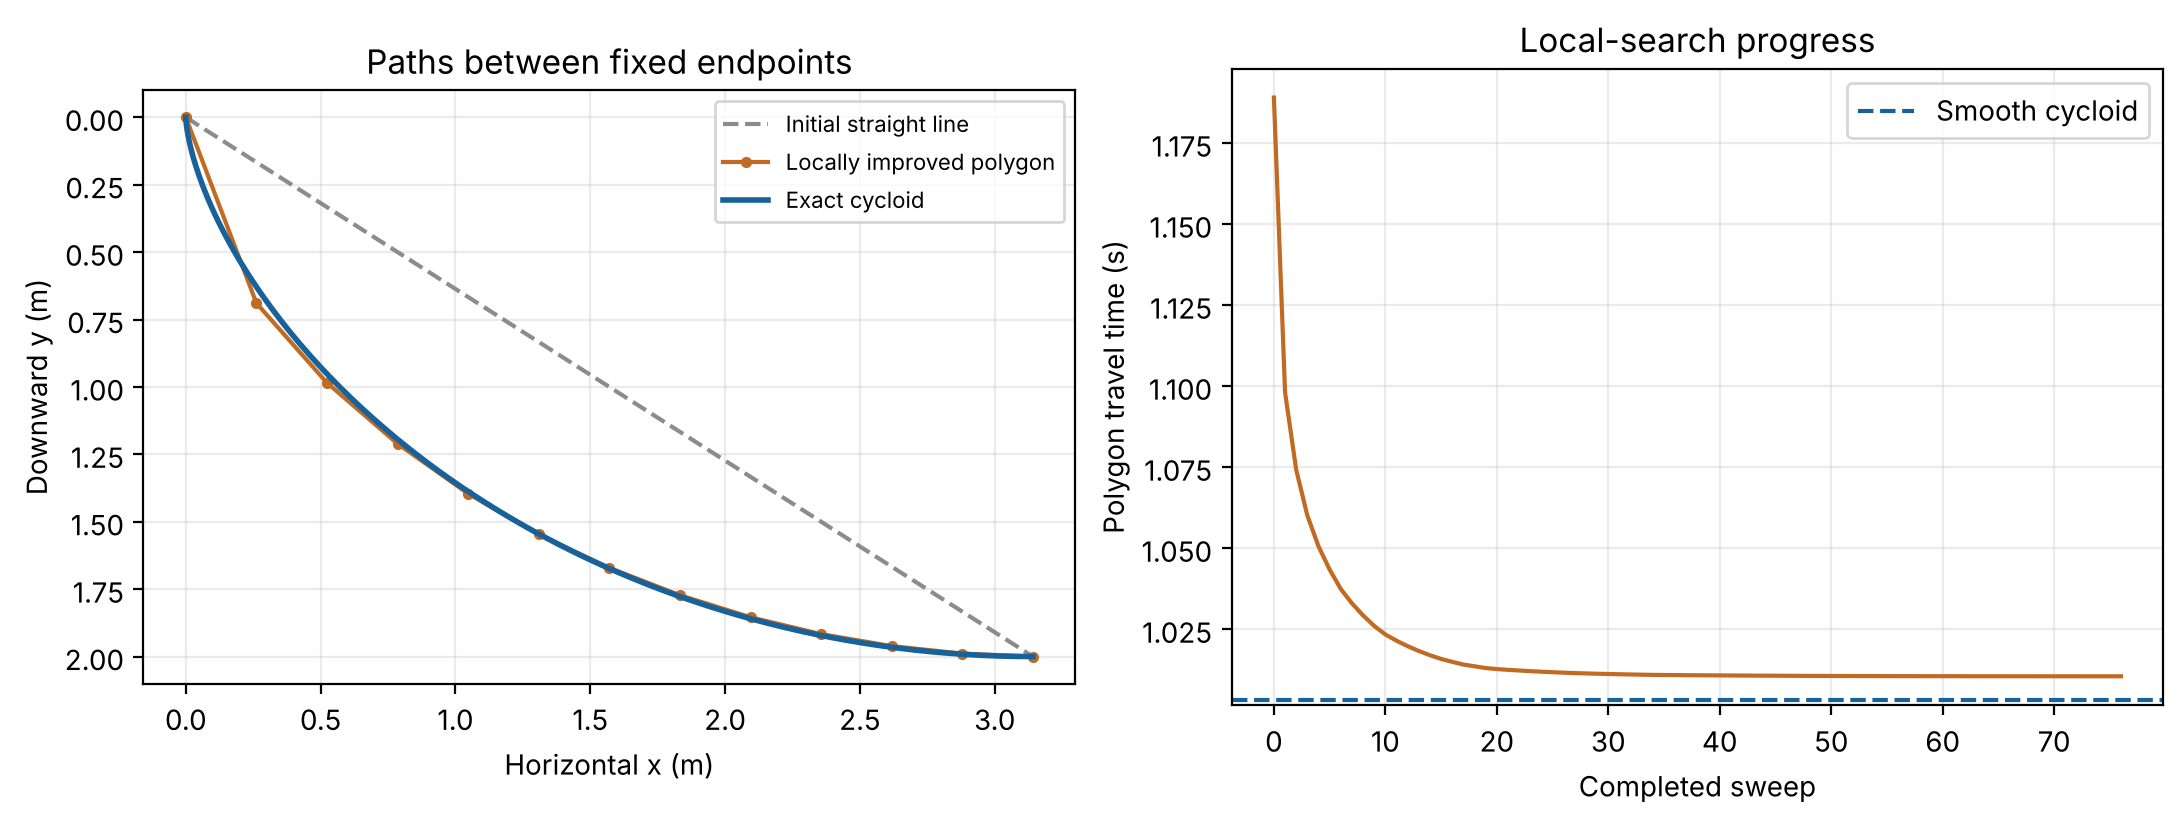

In [17]:
# Create two panels for the optimized polygon and its progress over sweeps.
fig, (shape_ax, progress_ax) = plt.subplots(1, 2, figsize=(10.8, 4.0), constrained_layout=True)
# Plot the starting straight track as a geometry reference.
shape_ax.plot([0.0, horizontal_distance], [0.0, vertical_drop], linestyle='--', color='#8c8c8c', label='Initial straight line')
# Plot the updated 12-piece polygon with its visible node locations.
shape_ax.plot(polygon_x, polygon_y, 'o-', markersize=3, color='#c06a22', label='Locally improved polygon')
# Plot the known smooth cycloid for a visual comparison, not as an optimizer input.
shape_ax.plot([point[0] for point in cycloid_points_100], [point[1] for point in cycloid_points_100], color='#17629a', linewidth=2, label='Exact cycloid')
# Make greater downward displacement appear physically lower.
shape_ax.invert_yaxis()
# Preserve geometric proportions in the path panel.
shape_ax.set_aspect('equal', adjustable='box')
# Label the coordinate units and the purpose of this comparison.
shape_ax.set(xlabel='Horizontal x (m)', ylabel='Downward y (m)', title='Paths between fixed endpoints')
# Keep the three paths identifiable while retaining a light grid.
shape_ax.grid(alpha=0.25)
# Show which curve came from the local numerical search.
shape_ax.legend(fontsize=8)
# Number the saved initial state and each completed sweep.
sweep_numbers = np.arange(len(search_history))
# Plot the measured total time after each local-search sweep.
progress_ax.plot(sweep_numbers, search_history, color='#c06a22')
# Mark the smooth global reference without implying the polygon attains it.
progress_ax.axhline(cycloid_exact_time, color='#17629a', linestyle='--', label='Smooth cycloid')
# Identify elapsed time rather than length or local segment cost.
progress_ax.set(xlabel='Completed sweep', ylabel='Polygon travel time (s)', title='Local-search progress')
# Provide a light grid and label for the reference line.
progress_ax.grid(alpha=0.25)
# Keep the analytical reference visible in the legend.
progress_ax.legend()
# Render both the changed shape and the algorithm history.
plt.show()

**Interpretation.** The numerical polygon bends toward the smooth cycloid and improves on the straight start, but it still has only 12 pieces. A non-increasing history shows that our code's local replacement rule behaved as intended. It does not establish that the last polygon is the best possible polygon, let alone prove the continuous brachistochrone theorem. Increasing resolution also increases the nested-loop work.



## 8. Historical candidate: a circular arc

Galileo studied circular tracks in the history of this problem. This makes a useful scientific question: **can a plausible-looking curve be fast without being fastest?** We construct the circle that starts at $A=(0,0)$ with a vertical tangent, stays to the right of $A$, and passes through $B=(L,H)$. Its center is $(R,0)$, where

$$R=\frac{L^2+H^2}{2L},\quad x(\phi)=R(1-\cos\phi),\quad y(\phi)=R\sin\phi,\quad \phi_1=2\arctan(L/H).$$

For our endpoint, the arc dips slightly below $B$ before rising to it. This remains feasible under the *frictionless track* model: the bead still has positive speed because its height remains below $A$. Its first downward tangent is vertical, yet its curvature differs from the cycloid. We approximate its time with chords and refine the sampling. This is a comparison of distinct admissible paths, **not** a proof about all circles or all paths.

In [18]:
# Determine the radius of the right-hand circle with a vertical tangent at A.
circle_radius = (horizontal_distance**2 + vertical_drop**2) / (2.0 * horizontal_distance)
# Find the parameter angle that reaches B on the first downward arch.
circle_end_angle = 2.0 * math.atan(horizontal_distance / vertical_drop)
# Define a reusable point sampler for this one circular candidate.
def circle_path(segments):
    # Explain the sampled output and the fixed endpoint geometry.
    """Return points on the vertical-tangent circular arc from A to B."""
    # Require at least one straight chord in the sampled path.
    if isinstance(segments, bool) or not isinstance(segments, int) or segments < 1:
        # Report invalid polygon resolution before dividing by it.
        raise ValueError('segments must be a positive integer')
    # Evaluate the circle coordinates at equally spaced parameter angles.
    return [(circle_radius * (1.0 - math.cos(circle_end_angle * index / segments)), circle_radius * math.sin(circle_end_angle * index / segments)) for index in range(segments + 1)]

# Sample a finely resolved circular track for its time and figure.
circle_points = circle_path(2000)
# Sum the exact time of every chord in the sampled circular track.
circle_time = path_time(circle_points)
# Show the time of this alternative alongside the exact cycloid reference.
print(f'Circular arc: {circle_time:.6f} s; cycloid: {cycloid_exact_time:.6f} s')
# Verify that the parameterized candidate reaches the same fixed endpoint.
assert np.allclose(circle_points[-1], end_point, atol=1e-12)
# Check that this particular circular candidate is slower than the smooth cycloid.
assert circle_time > cycloid_exact_time
# Check that the model does not encounter a point above the start level.
assert min(point[1] for point in circle_points) >= 0.0

Circular arc: 1.028483 s; cycloid: 1.003033 s


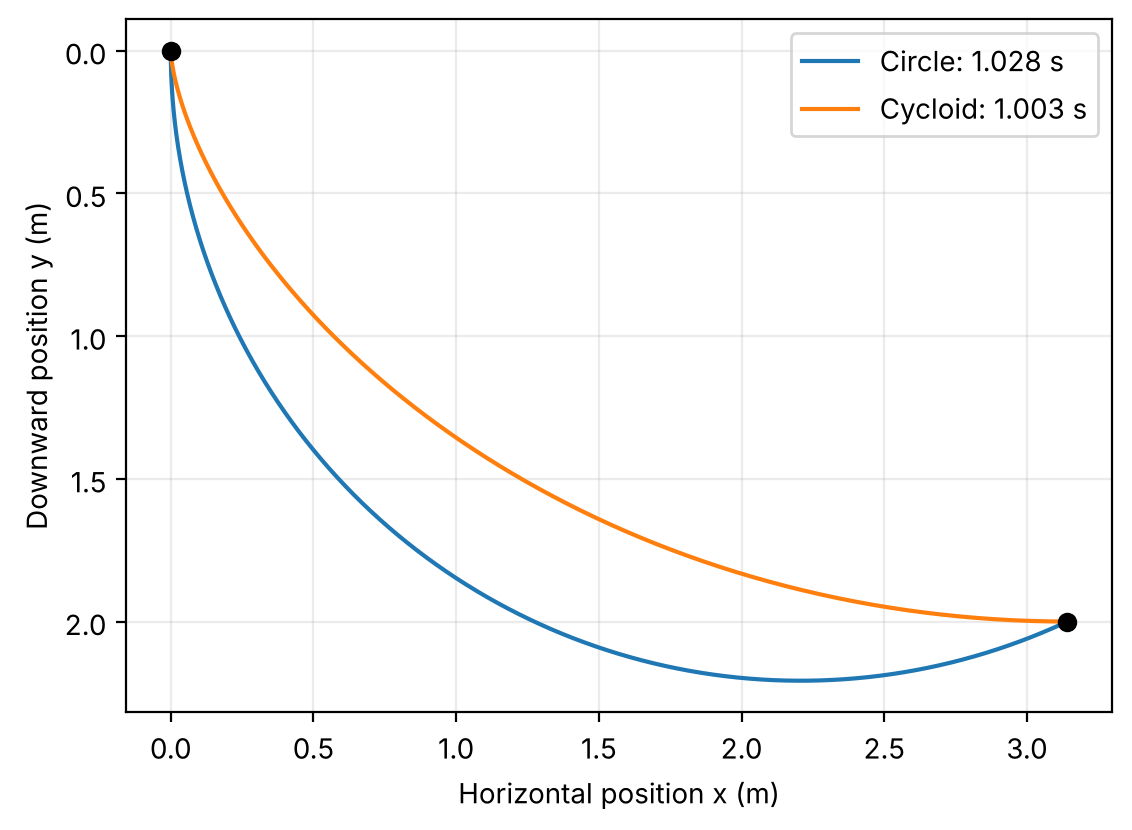

In [19]:
# Draw a joint figure to show how two different initially steep curves evolve.
fig, ax = plt.subplots(figsize=(7.5, 4.5))
# Draw the historical circular candidate using its sampled coordinates.
ax.plot([point[0] for point in circle_points], [point[1] for point in circle_points], label=f'Circle: {circle_time:.3f} s')
# Draw the cycloid already calculated for the same endpoints.
ax.plot([point[0] for point in cycloid_points_100], [point[1] for point in cycloid_points_100], label=f'Cycloid: {cycloid_exact_time:.3f} s')
# Mark the shared start and destination to make the comparison fair.
ax.scatter([0.0, horizontal_distance], [0.0, vertical_drop], color='black', zorder=3)
# Put greater downward displacement lower on the page.
ax.invert_yaxis()
# Use identical coordinate scales so neither shape is distorted.
ax.set_aspect('equal', adjustable='box')
# Name the horizontal distance and its unit.
ax.set_xlabel('Horizontal position x (m)')
# Name the downward coordinate and its unit.
ax.set_ylabel('Downward position y (m)')
# Add light reference lines for reading the curves.
ax.grid(alpha=0.25)
# Identify both curves and their approximate arrival times.
ax.legend()
# Display the candidate comparison next to its explanation.
plt.show()

**Checkpoint.** Both curves begin steeply, and the circular candidate is much faster than the straight track in this example. Yet its approximately 1.028 s exceeds the cycloid's approximately 1.003 s. The data distinguish these two tracks only. In the circular curve a small uphill finish is possible because the bead has already gained kinetic energy.

## 9. Least-time paths and refraction: a two-layer analogy

A second path-finding problem helps explain the mathematics. Imagine a ray travelling from $(0,0)$ to $(L,h_1+h_2)$ through two horizontal layers with **constant** speeds $v_1$ and $v_2$. It crosses the interface $y=h_1$ at the unknown horizontal coordinate $u$. Its total time is

$$T(u)=\frac{\sqrt{u^2+h_1^2}}{v_1}+\frac{\sqrt{(L-u)^2+h_2^2}}{v_2}.$$

Differentiate with respect to $u$ to obtain the minimum condition

$$\frac{u}{v_1\sqrt{u^2+h_1^2}}=\frac{L-u}{v_2\sqrt{(L-u)^2+h_2^2}},\quad\text{or}\quad \frac{\sin\alpha_1}{v_1}=\frac{\sin\alpha_2}{v_2},$$

where each angle $\alpha$ is measured from the **vertical interface normal**. This is Snell's least-time relation. A bead in gravity moves faster at greater depth, suggesting a continuum of increasingly fast layers and hence a bending route. Our two-layer ray is a **separate constant-speed model**; its $T(u)$ does not replace the bead's exact segment formula or prove the cycloid theorem.

In [20]:
# Choose a two-layer example with metres for lengths and metres per second for speeds.
layer_depth_1, layer_depth_2, layer_width = 1.0, 1.0, 2.0
# Let the second layer carry the ray twice as fast as the first.
layer_speed_1, layer_speed_2 = 2.0, 4.0
# Define total travel time as a function of the unknown interface crossing.
def two_layer_time(crossing):
    # Identify that crossing is a horizontal coordinate measured in metres.
    """Return total ray travel time in seconds for 0<=crossing<=width."""
    # Restrict the crossing to the physical interface between the endpoints.
    if not math.isfinite(crossing) or not 0.0 <= crossing <= layer_width:
        # Diagnose coordinates outside the allowed interface interval.
        raise ValueError('crossing must lie between zero and layer_width')
    # Compute the first geometric length and divide it by first-layer speed.
    first_time = math.hypot(crossing, layer_depth_1) / layer_speed_1
    # Compute the second geometric length and divide it by second-layer speed.
    second_time = math.hypot(layer_width - crossing, layer_depth_2) / layer_speed_2
    # Add the two elapsed times because the ray traverses both layers.
    return first_time + second_time

# Sample 1001 allowable interface positions to perform a transparent grid search.
interface_positions = np.linspace(0.0, layer_width, 1001)
# Calculate the time associated with each candidate interface crossing.
layer_times = np.array([two_layer_time(float(position)) for position in interface_positions])
# Locate the index of the fastest point on this finite candidate grid.
best_layer_index = int(np.argmin(layer_times))
# Recover the physical horizontal coordinate represented by that index.
best_crossing = float(interface_positions[best_layer_index])
# Calculate sin(alpha_1)/v_1 using the first path segment and vertical normal.
left_snell = best_crossing / (layer_speed_1 * math.hypot(best_crossing, layer_depth_1))
# Calculate sin(alpha_2)/v_2 in the same units from the second segment.
right_snell = (layer_width - best_crossing) / (layer_speed_2 * math.hypot(layer_width - best_crossing, layer_depth_2))
# Show the selected interface point, time, and two sides of Snell's relation.
print(f'Crossing u={best_crossing:.3f} m; T={layer_times[best_layer_index]:.4f} s')
# Report the small nonzero grid residual instead of claiming an exact root.
print(f'Snell sides: {left_snell:.6f} and {right_snell:.6f} s/m')
# A 0.002 m grid should make the relation nearly, though not exactly, equal.
assert abs(left_snell - right_snell) < 0.001

Crossing u=0.462 m; T=1.0094 s
Snell sides: 0.209702 and 0.209592 s/m


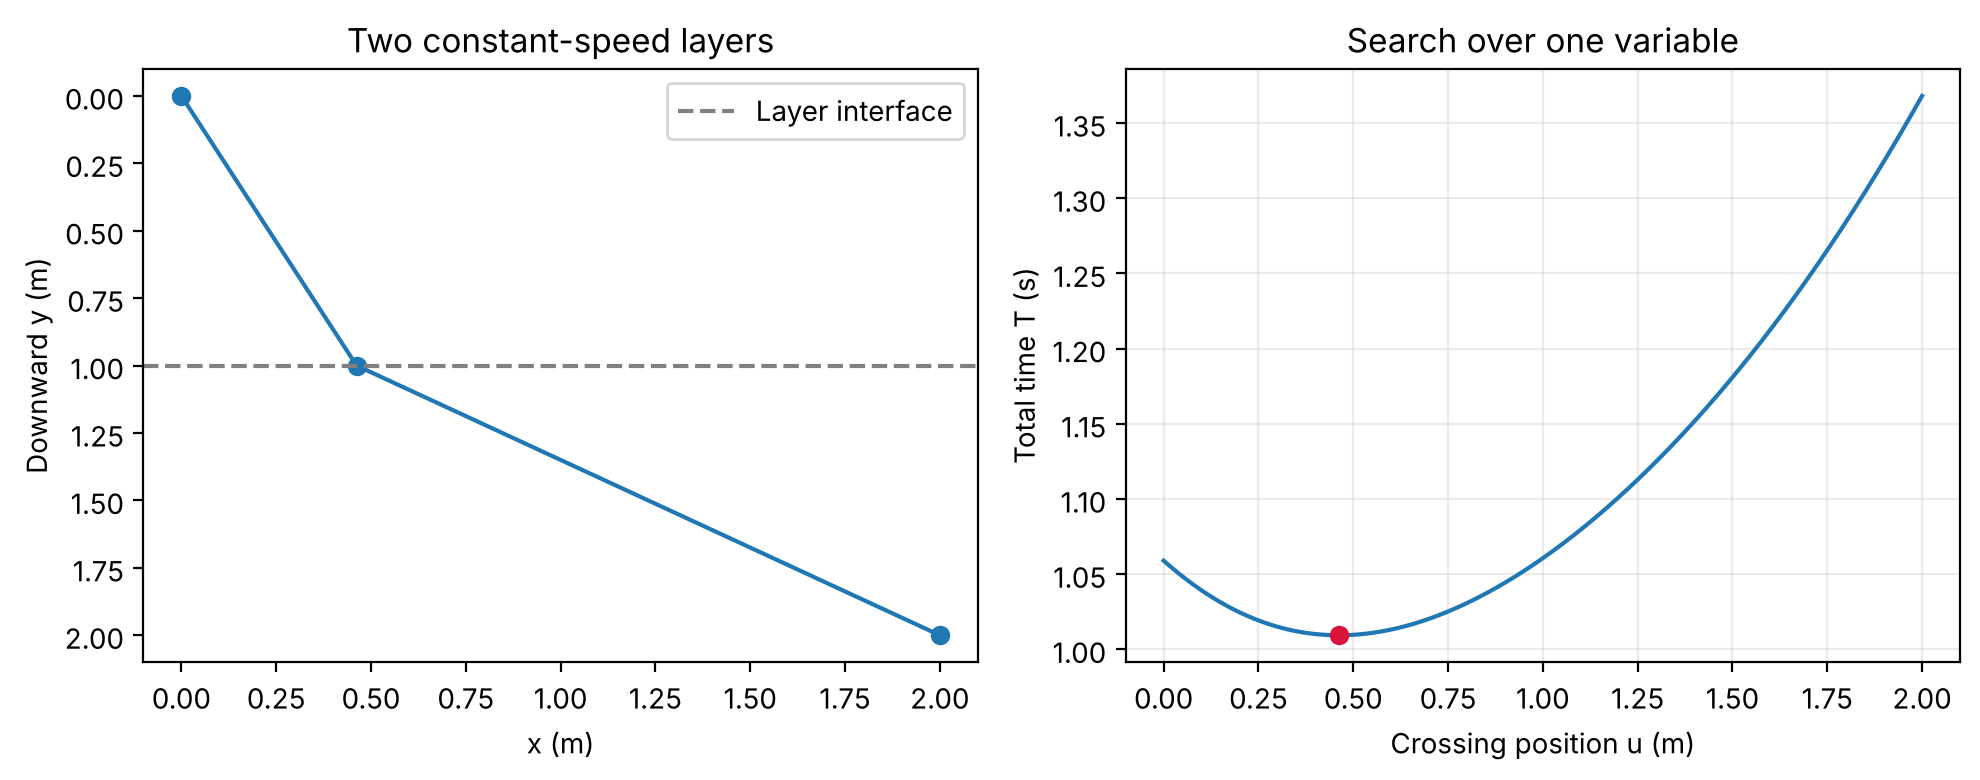

In [21]:
# Set up panels for the actual two-layer path and the numerical time search.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# Draw the least-time grid candidate as two joined straight segments.
axes[0].plot([0.0, best_crossing, layer_width], [0.0, layer_depth_1, layer_depth_1 + layer_depth_2], marker='o')
# Draw the interface across which speed changes suddenly.
axes[0].axhline(layer_depth_1, color='gray', linestyle='--', label='Layer interface')
# Put the first layer above the second in the physical sketch.
axes[0].invert_yaxis()
# Label both coordinate axes of the path geometry.
axes[0].set(xlabel='x (m)', ylabel='Downward y (m)', title='Two constant-speed layers')
# Identify the speed discontinuity without hiding the path.
axes[0].legend()
# Plot the time calculated for every candidate crossing position.
axes[1].plot(interface_positions, layer_times)
# Mark the best tested crossing on the sampled time curve.
axes[1].scatter([best_crossing], [layer_times[best_layer_index]], color='crimson', zorder=3)
# Identify the adjustable coordinate and objective with units.
axes[1].set(xlabel='Crossing position u (m)', ylabel='Total time T (s)', title='Search over one variable')
# Add subdued guide lines to the numerical plot.
axes[1].grid(alpha=0.25)
# Keep all text legible within the notebook's figure width.
fig.tight_layout()
# Render the physical analogy and one-dimensional optimization together.
plt.show()

**Checkpoint.** The crossing shifts toward the slower first layer: the path uses less horizontal travel there and more in the faster layer. The finite grid gives a small Snell residual, which can be reduced with a finer grid or root finder. Gravity instead changes bead speed continuously with depth, so the ray analogy is conceptual and the full bead calculation still uses $v(y)=\sqrt{2gy}$.

## 10. The equal-time descent property of the cycloid

The same cycloid has another classical property, called the **tautochrone** or equal-time descent. On the descending half from cusp $\theta=0$ to its bottom $\theta=\pi$, release a frictionless bead *from rest at a point $\theta_0$ on that curve*. The ideal time to reach the bottom is

$$T_{\text{bottom}}=\pi\sqrt{a/g},\qquad 0\leq\theta_0<\pi.$$

The start position changes, and so does the distance travelled, but this elapsed time remains the same. One way to see the relation is to measure arc distance $q$ **up the curve from its bottom**. The geometry gives $q=4a\cos(\theta/2)$, and tangential gravity gives $d^2q/dt^2=-(g/(4a))q$. This is simple harmonic motion; release from rest at any $q>0$ reaches $q=0$ after one quarter-period, $\pi\sqrt{a/g}$. For first-year study the code below is an independent numerical illustration. It translates each new release point to $(0,0)$ so the existing `path_time` function uses the correct **drop since release**.

The brachistochrone asks for minimum time **between fixed endpoints**; the tautochrone asks for equal time to the **bottom from different release points** on one track. The two questions are different even though the ideal curves have the same cycloidal shape.

In [22]:
# Select several release angles along the descending half-cycloid.
release_angles = [0.0, math.pi / 6.0, math.pi / 3.0, 2.0 * math.pi / 3.0]
# Keep the exact equal-time prediction as an independent reference.
equal_descent_time = math.pi * math.sqrt(cycloid_scale / g)
# Prepare to collect polygonal times from different release positions.
release_results = []
# Repeat the path-time computation for each new initial point.
for release_angle in release_angles:
    # Compute the original cycloid coordinates of this release point.
    release_x = cycloid_scale * (release_angle - math.sin(release_angle))
    # Compute its original downward coordinate relative to the cusp.
    release_y = cycloid_scale * (1.0 - math.cos(release_angle))
    # Sample the remaining track from release to the same bottom angle.
    remaining_angles = np.linspace(release_angle, math.pi, 1201)
    # Translate x and y so this release point becomes the new origin.
    remaining_path = [(cycloid_scale * (float(theta) - math.sin(float(theta))) - release_x, cycloid_scale * (1.0 - math.cos(float(theta))) - release_y) for theta in remaining_angles]
    # Sum the chord times using gravitational speed from the release height.
    measured_time = path_time(remaining_path)
    # Store each angle and time so they can be compared after the loop.
    release_results.append((release_angle, measured_time))
    # Display the numerical estimate and its discrepancy from the exact time.
    print(f'Release theta={release_angle:.3f}: polygon={measured_time:.6f} s, exact={equal_descent_time:.6f} s')
# Check numerical closeness without treating polygon estimates as exact curves.
assert max(abs(measured - equal_descent_time) for angle, measured in release_results) < 0.003

Release theta=0.000: polygon=1.003033 s, exact=1.003033 s
Release theta=0.524: polygon=1.003034 s, exact=1.003033 s
Release theta=1.047: polygon=1.003035 s, exact=1.003033 s
Release theta=2.094: polygon=1.003037 s, exact=1.003033 s


**Checkpoint.** The polygon estimates differ slightly because each smooth track portion has been replaced by chords. They cluster near the same exact time. Do not use the original `speed_at_drop(y)` unchanged for a new release point: its input must be the *drop since that new release*, which is why we translate the path.

## 11. Geometry, gravity, and dimensional scaling

We can ask a design question without recomputing an entire search. If all horizontal and downward coordinates are multiplied by a positive factor $k$, then every segment length scales by $k$ and every speed scales by $\sqrt{k}$, so each travel time scales by $\sqrt{k}$. If gravity changes from $g$ to $g_{\rm new}$ with the geometry fixed, time scales by $\sqrt{g/g_{\rm new}}$. The **shape** of the ideal fastest path relative to its endpoints is unchanged under a uniform size scaling or a change in constant $g$; the absolute time changes. This statement assumes the original frictionless point-bead model.

In general, choosing vertical drop $H$ as a length scale yields

$$T=\sqrt{H/g}\;F(L/H),$$

where $F$ is a dimensionless function that depends on the route's **dimensionless geometry**. For a fitted cycloid $F$ depends on the fitted end angle. We will check scaling on the cycloid and a straight track using our reusable functions. This links unit analysis with code reuse and parameter studies.

In [23]:
# Choose a fourfold uniform enlargement of the original fixed-endpoint geometry.
size_factor = 4.0
# Multiply both coordinate components of every cycloid sample by that factor.
large_cycloid_points = [(size_factor * x, size_factor * y) for x, y in cycloid_points_100]
# Calculate the enlarged polygon's time using the original gravitational field.
large_polygon_time = path_time(large_cycloid_points)
# Calculate the original polygon's time at the same chord resolution.
original_polygon_time = path_time(cycloid_points_100)
# Compare computed polygon times with the predicted square-root size scaling.
print(f'Size factor {size_factor:g}: polygon time ratio={large_polygon_time/original_polygon_time:.6f}; predicted={math.sqrt(size_factor):.6f}')
# Check exact scaling on the analytical cycloid time without chord error.
large_exact_time = cycloid_exact_time * math.sqrt(size_factor)
# Use a doubled gravity to test that the same polygon shape has a shorter time.
stronger_gravity = 2.0 * g
# Evaluate the fixed polygon under stronger gravity with the gravity parameter.
stronger_gravity_time = path_time(cycloid_points_100, stronger_gravity)
# Show the observed gravity ratio and the exact theoretical factor.
print(f'Doubled g: polygon time ratio={stronger_gravity_time/original_polygon_time:.6f}; predicted={1.0/math.sqrt(2.0):.6f}')
# Verify the size law to floating-point accuracy for the identical polygon shape.
assert math.isclose(large_polygon_time / original_polygon_time, math.sqrt(size_factor), rel_tol=1e-12)
# Verify the changed-gravity law with a separately evaluated path time.
assert math.isclose(stronger_gravity_time / original_polygon_time, 1.0 / math.sqrt(2.0), rel_tol=1e-12)
# Confirm the exact cycloid result obeys the same uniform scaling prediction.
assert math.isclose(large_exact_time, 2.0 * cycloid_exact_time, rel_tol=1e-12)

Size factor 4: polygon time ratio=2.000000; predicted=2.000000
Doubled g: polygon time ratio=0.707107; predicted=0.707107


## 12. Validation and common mistakes

| Check | What it catches | What it does not prove |
|:--|:--|:--|
| $v^2=2gy$ | An incorrect speed formula or unit conversion | Negligible friction in a real experiment |
| Split versus unsplit straight line | An error in segment summation | Correctness for all curved paths |
| Cycloid endpoint coordinates | A wrong parameter, scale, or sine/cosine sign | Global least-time optimality |
| Polygon-time convergence | Sampling error in the chosen curved path | Accuracy of an unrelated search family |
| Known cycloid time versus candidate times | Plausibility of the program's comparisons | A theorem about infinitely many paths |

Two pitfalls deserve emphasis. First, directly evaluating $ds/v$ at the starting cusp gives $0/0$; use the limit or our finite segment calculation. Second, `y` increases *downward* here. A conventional plot needs its vertical axis inverted to show this physical direction. Do not mix this convention with an upward-positive height in the energy equation.

In [24]:
# Collect invalid cases with labels so error handling can be tested systematically.
invalid_examples = [('negative drop', speed_at_drop, (-0.1,)), ('backwards x', segment_time, ((1.0, 0.5), (0.0, 1.0))), ('too few path points', path_time, ([(0.0, 0.0)],)), ('invalid cycloid angle', cycloid_path, (1.0, 0.0, 10))]
# Visit each case without interrupting the remaining notebook on an expected error.
for label, function, arguments in invalid_examples:
    # Try one deliberately invalid call from the list.
    try:
        # Unpack its argument tuple into the corresponding function.
        function(*arguments)
    # Catch only ValueError so unexpected programming failures remain visible.
    except ValueError as error:
        # Print the failing case and its explanatory message.
        print(f'{label}: expected error: {error}')
    # Treat silent acceptance as a failed defensive-programming test.
    else:
        # Stop Run All if the function accepted the invalid case.
        raise AssertionError(f'{label} was not rejected')

negative drop: expected error: drop must be nonnegative and gravity must be positive and finite
backwards x: expected error: path x coordinates must not decrease
too few path points: expected error: supply at least two points, beginning at (0, 0)
invalid cycloid angle: expected error: require scale>0, 0<theta_end<2*pi, and segments>=1


## 13. Independent practice

Try these in a new cell before examining the worked answer. Use metres, seconds, and metres per second in the appropriate places.

1. Calculate the speed after a 1 m downward drop. Explain why the bead's mass does not appear.
2. Calculate the time along a *vertical* 2 m track from rest using `path_time`. Check it with the elementary result $t=\sqrt{2H/g}$. Does this track reach the chosen endpoint $B=(\pi,2)$?
3. Explain why splitting the same straight track into two collinear pieces does not change `path_time`.
4. For a horizontal first segment at the starting height, explain the `inf` result. What physical assumption would have to change to make that segment traversable?
5. Use the cycloid formulas at $a=1$ m and $\theta=\pi/2$. What are $x$, $y$, and elapsed time? Check with Python.
6. If $g$ is doubled while the geometry and frictionless model remain the same, by what factor do the travel times change? Test the straight and cycloid formulas.
7. Explain why the 100-chord polygon has a time different from the exact cycloid even though every *individual segment* time is calculated exactly.
8. Optional: change the second endpoint to $(2,2)$ m and compare its fitted cycloid and straight times. Does the special condition $a=1,\theta=\pi$ still apply?
9. Calculate the radius of the vertical-tangent circle through $A$ and $B$. Why can a track that rises near the finish still be traversed under our assumptions?
10. For the two-layer ray, use the best tested crossing to compute both $\sin\alpha/v$ values. Why is their difference small rather than exactly zero?
11. Release the bead at $\theta_0=\pi/3$ on the descending half-cycloid. Estimate the travel time to its bottom, and explain why its initial speed is set to zero again.
12. If both endpoint distances are multiplied by 9 and gravity remains fixed, what is the factor for the ideal travel time? What is the factor if gravity is then multiplied by 4?

Read the next two cells after attempting the questions. A figure or a small residual is a check of a particular calculation, not proof of the mathematical minimum.

In [25]:
# Compute the speed for a one-metre drop in practice question one.
practice_speed = speed_at_drop(1.0)
# Define a vertical track whose x coordinate remains zero throughout.
vertical_track = [(0.0, 0.0), (0.0, vertical_drop)]
# Compute its time with the general segment formula.
practice_vertical_time = path_time(vertical_track)
# Compute the same result from constant acceleration over a vertical distance.
vertical_formula = math.sqrt(2.0 * vertical_drop / g)
# Evaluate cycloid coordinates at a quarter-turn of the generating circle.
half_pi = math.pi / 2.0
# Convert that parameter to a horizontal position in metres.
practice_x = cycloid_scale * (half_pi - math.sin(half_pi))
# Convert the same parameter to a downward drop in metres.
practice_y = cycloid_scale * (1.0 - math.cos(half_pi))
# Calculate elapsed time to that point from the cycloid time law.
practice_t = half_pi * math.sqrt(cycloid_scale / g)
# Evaluate the straight-track time when gravity is doubled.
straight_double_g = path_time(straight_points, gravity=2.0 * g)
# Evaluate the cycloid time when only gravity changes.
cycloid_double_g = cycloid_end_angle * math.sqrt(cycloid_scale / (2.0 * g))
# Display the speed and vertical-track time with units for the first two answers.
print(f'1–2. v(1 m)={practice_speed:.6f} m/s; vertical time={practice_vertical_time:.6f} s')
# Show the intermediate cycloid point and elapsed time for question five.
print(f'5. at theta=pi/2: x={practice_x:.6f} m, y={practice_y:.6f} m, t={practice_t:.6f} s')
# Show both ratios to test the common inverse-square-root gravity scaling.
print(f'6. time ratios: straight={straight_double_g/straight_time:.6f}, cycloid={cycloid_double_g/cycloid_exact_time:.6f}')
# Check the independently derived vertical free-fall time.
assert math.isclose(practice_vertical_time, vertical_formula, rel_tol=1e-12)
# Check the exact parameter values for theta=pi/2.
assert math.isclose(practice_x, math.pi / 2.0 - 1.0) and math.isclose(practice_y, 1.0)
# Check that both example times scale by one over square root of two.
assert math.isclose(straight_double_g / straight_time, 1.0 / math.sqrt(2.0), rel_tol=1e-12)
# Verify the same factor for the cycloid result.
assert math.isclose(cycloid_double_g / cycloid_exact_time, 1.0 / math.sqrt(2.0), rel_tol=1e-12)

1–2. v(1 m)=4.429447 m/s; vertical time=0.638551 s
5. at theta=pi/2: x=0.570796 m, y=1.000000 m, t=0.501517 s
6. time ratios: straight=0.707107, cycloid=0.707107


**Answer interpretations.** In question 1, $m$ cancels from $mgy=mv^2/2$. In question 2, a vertical track reaches $(0,2)$, **not** the selected endpoint $(\pi,2)$, so its short time is not a competing solution to the same endpoint problem. In question 3, each collinear piece has constant acceleration along the same line and the exact times add. In question 4, initial horizontal motion would need a nonzero initial push or another force; that would be a different model. For question 7, straight chords replace the smooth curve, so the *path geometry* changes even though each chord's time is exact. The second endpoint in question 8 uses fitted parameters; it is not the special half-cycloid with $a=1$ m. In question 9, $R=(\pi^2+4)/(2\pi)\approx2.207$ m; the slight rise remains below the start, and energy already gained supplies positive speed. In question 10, the sides are about $0.20970$ and $0.20959$ s/m; a finite grid need not land exactly on the continuous optimum. In question 11, the exact time is $\pi/\sqrt{g}\approx1.003033$ s: the *new* release is from rest at its own starting height. In question 12, a size factor of 9 gives a time factor of 3; multiplying gravity by 4 subsequently gives a combined factor of $3/2$.

### Conclusion

The fastest path is a problem about **time**, which combines distance and changing speed. Python let us express a physical model, compare candidate algorithms and paths, visualize the result, and distinguish exact segment calculations from approximations of curved tracks. The cycloid is the analytical answer under the stated assumptions; finite numerical experiments support and illustrate it without replacing its mathematical proof.

### Further reading

- Eric A. Carlen, [*Note on the Brachistochrone Problem*](https://sites.math.rutgers.edu/~carlen/292S13/brach.pdf), Rutgers University (2013). Includes an advanced proof of global minimality.
- Daniel Liberzon, [*Brachistochrone*](https://liberzon.csl.illinois.edu/teaching/cvoc/node24.html), University of Illinois course notes. Explains the physical setup and the travel-time functional.
- Carl Mungan, [*Brachistochrone*](https://www.usna.edu/Users/physics/mungan/_files/documents/Scholarship/Brachistochrone.pdf), United States Naval Academy. Derives the cycloid parameterization and travel-time relation.

- David Meyer, *A Few Notes on the Brachistochrone Problem* (2024), course reading. Discusses Galileo, the cycloid, and the tautochrone.
- Alan Chen, *“Ground-Up” Solution to the Brachistochrone Problem* (2026), *National High School Journal of Science* (NHSJS). Develops segment-time reasoning and the Snell analogy.
- [*Brachistochrone curve*](https://en.wikipedia.org/wiki/Brachistochrone_curve), Wikipedia. Introductory history and terminology; use the mathematical references above for derivations.

The notebook derives the formulas needed for its calculations and uses these sources for deeper mathematical context. The derivation of the global theorem is optional reading beyond this notebook.